# 🎮 🛠️ Practical: translating Spanish to English with a _Transformer_ 🤖

In this practical we build the encoder-decoder `Transformer` 🤖 from *Attention Is All You Need* (Vaswani et al., 2017) piece by piece, train it to translate Spanish into English, and then look inside it to see which Spanish words it attends to while it writes each English word.

This is inspired and adapted from a [_keras_ tutorial](https://www.tensorflow.org/text/tutorials/transformer)

This is the architecture that the large language models we study in this course grew out of. A GPT-style model is essentially the **decoder half** of what we build here, with the encoder and the cross-attention removed. By the end you should be able to point at each part of the model and say what it does and why it is there.

**Before you start:** in the Colab menu choose *Runtime → Change runtime type → T4 GPU*, then run the cells from top to bottom. Everything (data download, tokenizers, model) happens inside this notebook, and there is nothing to install.

**What we will do**

1. Load the data and turn sentences into integer ids.
2. Meet attention and positional encoding in plain NumPy on a four-word sentence.
3. Rebuild the same ideas as Keras layers: attention layers, feed-forward, encoder, decoder.
4. Assemble and train the Transformer.
5. Translate sentences and plot the attention weights.
6. Try some experiments.

**Differences from the original paper (so you are not surprised)**

* We use a simple word-level tokenizer rather than the subword tokenizers real LLMs use. Part 1 and the exercises come back to this.
* The model is smaller (4 layers, 128-dimensional) so that it trains in minutes, not days.
* Source and target languages use separate embedding matrices.

*Credits:* this notebook is adapted from the TensorFlow tutorial "Neural machine translation with a Transformer and Keras" (code under Apache 2.0, text under CC BY 4.0), rewritten to be more incremental and more heavily commented. The sentence pairs come from the Tatoeba project (CC BY 2.0 FR) as packaged by manythings.org/anki.

## Part 0: Setup

Colab already ships with TensorFlow, Keras, NumPy and Matplotlib, and our data is a small text file that Keras downloads for us, so there is **nothing to install** in this notebook.

In [1]:
import pathlib                         # file paths
import random                          # shuffling the sentence pairs
import warnings                        # lets us hide a few harmless Keras warnings below
import numpy as np                     # plain numerical arrays, used for the "by hand" demos
import matplotlib.pyplot as plt        # plotting
import tensorflow as tf                # the deep-learning library (Keras lives inside it)

print("TensorFlow version:", tf.__version__)

# A GPU makes training many times faster. Check that Colab gave us one.
gpus = tf.config.list_physical_devices("GPU")
print("GPUs found:", gpus)
if not gpus:
    print("WARNING: no GPU found. Use Runtime -> Change runtime type -> T4 GPU, "
          "otherwise training will be very slow.")

# Keras prints some harmless warnings about masks and tiny softmaxes while we generate
# text one word at a time. They do not affect results, so we hide them to keep output readable.
warnings.filterwarnings("ignore", message=".*softmax over axis.*")
warnings.filterwarnings("ignore", message=".*does not support masking.*")

tf.get_logger().setLevel("ERROR")      # hide TensorFlow's chatty autograph notices

# Fix the random seeds so that everybody gets similar results when re-running.
tf.keras.utils.set_random_seed(42)

TensorFlow version: 2.21.0
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Part 1: The data

We use a Spanish-English sentence-pair collection: about 119,000 short, everyday sentences from the Tatoeba project, packaged for language learners by the Anki / ManyThings website. Every line of the file holds an English sentence and its Spanish translation, separated by a tab. We will translate **Spanish into English**.

The download tries three addresses in turn. If your network blocks all of them, download `spa-eng.zip` from <https://www.manythings.org/anki/> in your browser, unzip it, drag `spa.txt` into the Colab file panel (left sidebar, folder icon), and re-run the cell: it picks up `spa.txt` automatically.

In [2]:
DATA_URLS = [
    "https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip",
    "http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip",
    "https://www.manythings.org/anki/spa-eng.zip",
]

def find_spa_txt():
    # 1) If you uploaded spa.txt yourself, use that.
    for candidate in [pathlib.Path("spa.txt"), pathlib.Path("/content/spa.txt")]:
        if candidate.exists():
            return candidate

    # 2) Otherwise try each download address in turn until one works.
    for number, url in enumerate(DATA_URLS):
        try:
            archive = pathlib.Path(tf.keras.utils.get_file(
                fname=f"spa-eng-{number}.zip", origin=url,
                extract=True, cache_subdir=f"spa_eng_{number}"))
            folder = archive.parent if archive.is_file() else archive
            matches = list(folder.rglob("spa.txt"))      # search the unzipped folder for the file
            if matches:
                return matches[0]
        except Exception as error:
            print(f"Download from {url} failed: {error}")

    raise RuntimeError("Could not download the data. See the instructions above this cell "
                       "for how to upload spa.txt by hand.")

spa_txt_path = find_spa_txt()
print("Using data file:", spa_txt_path)

2638744/2638744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Using data file: /root/.keras/spa_eng_0/spa-eng-0_extracted/spa-eng/spa.txt


In [3]:
# Read the file. Each line looks like:  English sentence <TAB> Spanish sentence [<TAB> credits]
# We store pairs as (source, target) = (Spanish, English), because we translate Spanish -> English.
pairs = []
with open(spa_txt_path, encoding="utf-8") as file:
    for line in file:
        columns = line.rstrip("\n").split("\t")
        if len(columns) >= 2 and columns[0].strip() and columns[1].strip():
            english, spanish = columns[0].strip(), columns[1].strip()
            pairs.append((spanish, english))

# Shuffle (with a fixed seed so that everybody gets the same split), then cut into three parts.
random.Random(42).shuffle(pairs)
val_pairs_list = pairs[:3000]          # used to monitor training
test_pairs_list = pairs[3000:6000]     # used only at the end, to look at translations
train_pairs_list = pairs[6000:]        # everything else: what the model learns from

def to_dataset(pair_list):
    # Turn a Python list of (spanish, english) pairs into a tf.data.Dataset of string pairs.
    spanish_sentences = [spanish for spanish, english in pair_list]
    english_sentences = [english for spanish, english in pair_list]
    return tf.data.Dataset.from_tensor_slices((spanish_sentences, english_sentences))

train_examples = to_dataset(train_pairs_list)
val_examples = to_dataset(val_pairs_list)
test_examples = to_dataset(test_pairs_list)

print("Training pairs:  ", len(train_pairs_list))
print("Validation pairs:", len(val_pairs_list))
print("Test pairs:      ", len(test_pairs_list))
print()

# Look at five random training pairs.
for spanish, english in random.Random(0).sample(train_pairs_list, 5):
    print("ES:", spanish)
    print("EN:", english)
    print()

Training pairs:   112964
Validation pairs: 3000
Test pairs:       3000

ES: Golondrinas vuelan por los cielos.
EN: Swallows are flying in the sky.

ES: La decisión era tuya.
EN: The decision was yours.

ES: Todos parecen ser optimistas.
EN: Everyone seems optimistic.

ES: El lugar está casi desierto.
EN: The place is almost deserted.

ES: Te lo agradezco de todo corazón.
EN: I thank you from the bottom of my heart.



**A caveat about this dataset.** The same English sentence often appears several times with slightly different Spanish translations, so a validation sentence may have a near-twin in the training set. Validation scores here are therefore somewhat optimistic. (See question 5 at the end.)

Next we choose a few settings that apply to the whole practical. We keep only short sentences, because the cost of attention grows with the square of the sequence length, and because short sentences train much faster.

In [4]:
MAX_WORDS = 20          # keep only sentence pairs where both sentences have <= 20 tokens
MAX_LEN = MAX_WORDS + 2 # the English target also gets a [start] and an [end] token, so +2
VOCAB_SIZE = 10000      # each language keeps its 10,000 most frequent words
BATCH_SIZE = 128        # how many sentence pairs we process at once
BUFFER_SIZE = 20000     # how many examples we shuffle at once

**Cleaning the text.** Our tokenizer will split sentences on spaces. In this data, punctuation is stuck to the words (`biblioteca?`), and Spanish uses an upside-down `¿` and `¡`. We want every punctuation mark to be its own token, and we want everything in lowercase, so that `Hola`, `hola` and `HOLA` are one word. This small function does both. It will be used by every tokenizer below.

In [5]:
def standardize_text(text):
    # `text` is a TensorFlow string tensor (one sentence or a whole batch of them).
    text = tf.strings.lower(text, encoding="utf-8")     # lowercase, including accented letters
    # Put a space on both sides of every punctuation mark: "hola, amigo?" -> "hola , amigo ? "
    text = tf.strings.regex_replace(text, r'([.,!?;:¿¡()"])', r" \1 ")
    return tf.strings.strip(text)                       # remove spaces at the very start and end

example = tf.constant("¿Dónde está la BIBLIOTECA, por favor?")
print(standardize_text(example).numpy().decode("utf-8"))

¿ dónde está la biblioteca ,  por favor ?


In [6]:
def is_short_enough(spanish, english):
    # tf.strings.split cuts a string on spaces; tf.size counts the pieces = number of tokens.
    n_spanish_words = tf.size(tf.strings.split(standardize_text(spanish)))
    n_english_words = tf.size(tf.strings.split(standardize_text(english)))
    # Keep the pair only if both sentences are non-empty and not too long.
    both_short = tf.logical_and(n_spanish_words <= MAX_WORDS, n_english_words <= MAX_WORDS)
    both_non_empty = tf.logical_and(n_spanish_words > 0, n_english_words > 0)
    return tf.logical_and(both_short, both_non_empty)

train_pairs = train_examples.filter(is_short_enough)
val_pairs = val_examples.filter(is_short_enough)

# Count how many training pairs survived the filter (one quick pass over the data).
n_kept = train_pairs.reduce(np.int64(0), lambda count, _: count + 1).numpy()
print("Training pairs kept:", n_kept, "of", len(train_pairs_list))

Training pairs kept: 112643 of 112964


**Tokenization: words to integers.** A neural network cannot read text, only numbers. A tokenizer builds a vocabulary (a numbered list of words) and replaces every word by its number. Keras has a ready-made layer for this, `TextVectorization`. First let us watch it work on a tiny example.

In [7]:
toy_sentences = ["¿Dónde está el gato?", "El perro está aquí.", "El gato está aquí."]

# standardize=standardize_text means: clean each sentence with our function first.
# output_sequence_length=8 means: every sentence is padded (or cut) to exactly 8 ids.
toy_vectorizer = tf.keras.layers.TextVectorization(standardize=standardize_text,
                                                   output_sequence_length=8)

# adapt() reads the sentences and builds the vocabulary, most frequent word first.
toy_vectorizer.adapt(toy_sentences)

# Id 0 is always reserved for padding (shown as an empty string),
# and id 1 is always reserved for "unknown word" ([UNK]).
print("Vocabulary:", [str(word) for word in toy_vectorizer.get_vocabulary()])
print()
print("Ids:\n", toy_vectorizer(toy_sentences).numpy())   # shape (3 sentences, 8 positions)
print()

# A word that was not in the adapt() data becomes id 1 ([UNK]).
print("Unknown word:", toy_vectorizer(["El caballo está aquí."]).numpy())

Vocabulary: ['', '[UNK]', 'está', 'el', 'gato', 'aquí', '.', '¿', 'perro', 'dónde', '?']

Ids:
 [[ 7  9  2  3  4 10  0  0]
 [ 3  8  2  5  6  0  0  0]
 [ 3  4  2  5  6  0  0  0]]

Unknown word: [[3 1 2 5 6 0 0 0]]


Now the real tokenizers: one for Spanish, one for English. The English one is special. We wrap every English sentence in `[start]` and `[end]` markers, so that the model learns where a sentence begins (we will start generation from `[start]`) and where it stops (it learns to output `[end]`).

In [8]:
# Spanish (the input language): sentences padded/cut to MAX_WORDS ids.
es_vectorizer = tf.keras.layers.TextVectorization(max_tokens=VOCAB_SIZE,
                                                  standardize=standardize_text,
                                                  output_sequence_length=MAX_WORDS)

# English (the output language): padded/cut to MAX_LEN ids, because of [start] and [end].
en_vectorizer = tf.keras.layers.TextVectorization(max_tokens=VOCAB_SIZE,
                                                  standardize=standardize_text,
                                                  output_sequence_length=MAX_LEN)

def add_start_end(english_text):
    # "hello world"  ->  "[start] hello world [end]"
    return "[start] " + english_text + " [end]"

# Build the two vocabularies from the training data only (never from validation data!).
# We feed the text in batches of 1024 sentences because that is much faster than one by one.
es_vectorizer.adapt(train_pairs.map(lambda es, en: es).batch(1024))
en_vectorizer.adapt(train_pairs.map(lambda es, en: add_start_end(en)).batch(1024))

# Keep the vocabularies as ordinary Python lists of strings so we can turn ids back into words.
es_vocab = [str(word) for word in es_vectorizer.get_vocabulary()]
en_vocab = [str(word) for word in en_vectorizer.get_vocabulary()]

print("Spanish vocabulary size:", len(es_vocab))
print("English vocabulary size:", len(en_vocab))
print("First 12 English words:", en_vocab[:12])

# We will need the ids of the special tokens later, when we generate translations.
start_id = en_vocab.index("[start]")
end_id = en_vocab.index("[end]")
print("[start] has id", start_id, "and [end] has id", end_id)

Spanish vocabulary size: 10000
English vocabulary size: 10000
First 12 English words: ['', '[UNK]', '[start]', '[end]', '.', 'the', 'i', 'to', 'you', 'tom', 'a', '?']
[start] has id 2 and [end] has id 3


**Teacher forcing.** To train a translator we show the model the Spanish sentence *and the English sentence so far*, and ask it to predict the next English word, at every position at once. So from one English sentence we make two sequences that are shifted by one step: the **decoder input** (everything except the last token) and the **labels** (everything except the first token). At each position, the label is simply "the next word".

The function below does the tokenization and the shift, and then we wrap everything in a `tf.data` pipeline that shuffles the data and serves batches.

In [9]:
def prepare_batch(spanish, english):
    # Both arguments are *batches* of strings, shape (batch,).
    source_ids = es_vectorizer(spanish)                     # (batch, MAX_WORDS)
    target_ids = en_vectorizer(add_start_end(english))      # (batch, MAX_LEN)

    # Teacher forcing: the decoder sees [start] w1 w2 ... and must predict w1 w2 ... [end].
    decoder_inputs = target_ids[:, :-1]   # drop the last token   -> (batch, MAX_LEN - 1)
    labels = target_ids[:, 1:]            # drop the first token  -> (batch, MAX_LEN - 1)

    # Keras expects ((model inputs), labels). The model gets TWO inputs.
    return (source_ids, decoder_inputs), labels

def make_batches(dataset):
    return (dataset
            .shuffle(BUFFER_SIZE)                  # random order each epoch
            .batch(BATCH_SIZE)                     # group into batches of 128 pairs
            .map(prepare_batch, tf.data.AUTOTUNE)  # tokenize + shift, whole batch at once
            .prefetch(tf.data.AUTOTUNE))           # prepare the next batch while the GPU is busy

train_batches = make_batches(train_pairs)
val_batches = make_batches(val_pairs)

In [10]:
# Grab one batch and inspect it.
(source_ids, decoder_inputs), labels = next(iter(train_batches))

print("source_ids     :", source_ids.shape, "(batch, Spanish positions)")
print("decoder_inputs :", decoder_inputs.shape, "(batch, English positions)")
print("labels         :", labels.shape, "(same shape as decoder_inputs)")

def ids_to_words(ids, vocab):
    # Turn a row of ids back into text, skipping the padding id 0.
    return " ".join(vocab[i] for i in ids if i != 0)

print()
print("Spanish:", ids_to_words(source_ids[0].numpy(), es_vocab))
print()

# Side by side: at every position the label is the *next* word of the decoder input.
print(f"{'position':>8} | {'decoder input':<14} | {'label (next word)':<14}")
for position in range(8):
    input_word = en_vocab[decoder_inputs[0, position].numpy()] or "(padding)"   # id 0 = padding
    label_word = en_vocab[labels[0, position].numpy()] or "(padding)"
    print(f"{position:>8} | {input_word:<14} | {label_word:<14}")

source_ids     : (128, 20) (batch, Spanish positions)
decoder_inputs : (128, 21) (batch, English positions)
labels         : (128, 21) (same shape as decoder_inputs)

Spanish: dios te ama y tiene un maravilloso plan para tu vida .

position | decoder input  | label (next word)
       0 | [start]        | god           
       1 | god            | loves         
       2 | loves          | you           
       3 | you            | and           
       4 | and            | has           
       5 | has            | a             
       6 | a              | wonderful     
       7 | wonderful      | plan          


## Part 2: Attention in plain NumPy

Before any Keras, let us compute attention by hand on a four-word sentence, so that we can see every number.

The idea is a **fuzzy dictionary lookup**. Every word produces three vectors:

* a **query**: what this word is looking for,
* a **key**: what this word offers, so that others can find it,
* a **value**: the information this word hands over if it is selected.

A word compares its query with every key (a dot product, large when they match), turns those scores into weights that sum to 1 (softmax), and returns the weighted average of all the values.

In [11]:
np.random.seed(0)

words = ["the", "cat", "sat", "down"]
d = 4   # every vector has 4 numbers; real models use 64 to 128 per head or more

# Pretend these are the embeddings of our four words: one row per word.  Shape (4 words, 4 numbers).
embeddings = np.round(np.random.randn(4, d), 2)

# Three weight matrices turn each embedding into a query, a key and a value.
# In a real model these are LEARNED; here they are random numbers.
W_query = np.round(np.random.randn(d, d), 2)
W_key = np.round(np.random.randn(d, d), 2)
W_value = np.round(np.random.randn(d, d), 2)

# (4,4) @ (4,4) -> (4,4): each row (one word) is multiplied by the matrix.
queries = embeddings @ W_query
keys = embeddings @ W_key
values = embeddings @ W_value

print("queries shape:", queries.shape, "  keys shape:", keys.shape, "  values shape:", values.shape)

# A small helper so that we can print tables of numbers with word labels.
def show_table(matrix, row_labels, column_labels, title):
    print(title)
    print(" " * 6 + "".join(f"{label:>8}" for label in column_labels))
    for label, row in zip(row_labels, matrix):
        print(f"{label:>6}" + "".join(f"{value:8.2f}" for value in row))
    print()

queries shape: (4, 4)   keys shape: (4, 4)   values shape: (4, 4)


In [12]:
# Step 1: scores. scores[i, j] says "how well does word i's query match word j's key?"
# We use explicit loops so that you can see exactly what is happening.
scores = np.zeros((4, 4))
for i in range(4):          # i = the word that is looking (the query)
    for j in range(4):      # j = the word being looked at (the key)
        # Dot product = a similarity measure. We divide by sqrt(d) so the scores do not get
        # huge when the vectors are long (huge scores make softmax almost one-hot and
        # make learning hard).
        scores[i, j] = np.dot(queries[i], keys[j]) / np.sqrt(d)

show_table(scores, words, words, "Scores (rows = who is looking, columns = who is looked at):")

Scores (rows = who is looking, columns = who is looked at):
           the     cat     sat    down
   the  -22.01  -21.58   -3.29   -7.70
   cat   -6.11   -6.65   -1.30   -1.87
   sat   -8.99   -9.48   -0.76   -3.36
  down   -5.55   -4.85   -1.21   -1.82



In [13]:
# Step 2: softmax turns each row of scores into positive weights that sum to 1.
def softmax(row_of_scores):
    # Subtracting the maximum changes nothing mathematically but avoids overflow in exp().
    shifted = row_of_scores - np.max(row_of_scores)
    exponentials = np.exp(shifted)
    return exponentials / exponentials.sum()

weights = np.zeros((4, 4))
for i in range(4):
    weights[i] = softmax(scores[i])

show_table(weights, words, words, "Attention weights:")
print("Each row sums to:", weights.sum(axis=1))   # should be [1. 1. 1. 1.]

Attention weights:
           the     cat     sat    down
   the    0.00    0.00    0.99    0.01
   cat    0.01    0.00    0.63    0.36
   sat    0.00    0.00    0.93    0.07
  down    0.01    0.02    0.63    0.34

Each row sums to: [1. 1. 1. 1.]


In [14]:
# Step 3: each word's output is the weighted average of ALL the values.
outputs = np.zeros((4, d))
for i in range(4):
    for j in range(4):
        # Add word j's value vector, scaled by how much word i attends to word j.
        outputs[i] = outputs[i] + weights[i, j] * values[j]

print("outputs shape:", outputs.shape, "  (same shape as the input: one new vector per word)")
print("New vector for 'cat':", np.round(outputs[1], 2))

# The same thing with one matrix multiplication (this is what real code does):
print("Same result with a matrix product?", np.allclose(outputs, weights @ values))

outputs shape: (4, 4)   (same shape as the input: one new vector per word)
New vector for 'cat': [-1.2  -0.7  -1.22 -1.68]
Same result with a matrix product? True


**The causal mask.** In the *encoder* every word may look at every other word, in both directions. But the *decoder* writes the translation one word at a time, so while it is predicting word *t* it must not be allowed to peek at words *t+1, t+2, ...* (during training those words are right there in the input, so peeking would be cheating). We forbid it by setting the scores of future positions to minus infinity before the softmax, which turns their weights into exactly 0.

In [15]:
causal_scores = scores.copy()
for i in range(4):
    for j in range(4):
        if j > i:                          # word j comes AFTER word i, so word i may not see it
            causal_scores[i, j] = -np.inf  # exp(-infinity) = 0, so the weight becomes 0

causal_weights = np.zeros((4, 4))
for i in range(4):
    causal_weights[i] = softmax(causal_scores[i])

show_table(causal_weights, words, words, "Causal attention weights (zeros above the diagonal):")

Causal attention weights (zeros above the diagonal):
           the     cat     sat    down
   the    1.00    0.00    0.00    0.00
   cat    0.63    0.37    0.00    0.00
   sat    0.00    0.00    1.00    0.00
  down    0.01    0.02    0.63    0.34



**Multi-head attention** simply does this several times in parallel with different weight matrices (the "heads"), each free to look for a different relationship (for example one head may track the previous word, another the subject of the sentence), and then glues the results together. Real Transformers also use a second kind of mask, the **padding mask**, which stops words from attending to the padding positions we added to make all sentences the same length.

**Cross-attention** is the same computation with one change: the queries come from one sequence (the English words being written) while the keys and values come from another (the Spanish sentence). This is how the decoder "reads" the source sentence.

## Part 3: Positional encoding

Look back at the attention computation: nothing in it depends on the *order* of the words. If we shuffled the rows of `embeddings`, we would get the same outputs, just shuffled. For attention, "how are you", "how you are" and "you how are" are the same bag of words.

To give the model a sense of order, we **add** a position-dependent vector to each word's embedding. The original paper uses sines and cosines of many different frequencies, so every position gets its own unique pattern, and nearby positions get similar patterns.

In [16]:
def positional_encoding(length, depth):
    # Returns an array of shape (length, depth): one vector of `depth` numbers per position.
    half = depth // 2                                   # half the channels use sin, half use cos

    positions = np.arange(length)[:, np.newaxis]        # (length, 1)  = 0, 1, 2, ...
    channel_index = np.arange(half)[np.newaxis, :] / half   # (1, half) = numbers from 0 up to 1

    # Each channel gets its own wavelength: channel 0 oscillates fast, the last channel very slowly.
    angle_rates = 1 / (10000 ** channel_index)          # (1, half)
    angles = positions * angle_rates                    # (length, half), by broadcasting

    # NOTE: the paper interleaves sin and cos channels; we put all sines first and then all
    # cosines. The model cannot tell the difference, and this is easier to write and to plot.
    return np.concatenate([np.sin(angles), np.cos(angles)], axis=-1)   # (length, depth)

# Tiny example: 5 positions, 8 channels. Look at the first 4 columns (sines): they change
# fast from row to row. The last columns change slowly.
print(np.round(positional_encoding(5, 8), 2))

[[ 0.    0.    0.    0.    1.    1.    1.    1.  ]
 [ 0.84  0.1   0.01  0.    0.54  1.    1.    1.  ]
 [ 0.91  0.2   0.02  0.   -0.42  0.98  1.    1.  ]
 [ 0.14  0.3   0.03  0.   -0.99  0.96  1.    1.  ]
 [-0.76  0.39  0.04  0.   -0.65  0.92  1.    1.  ]]


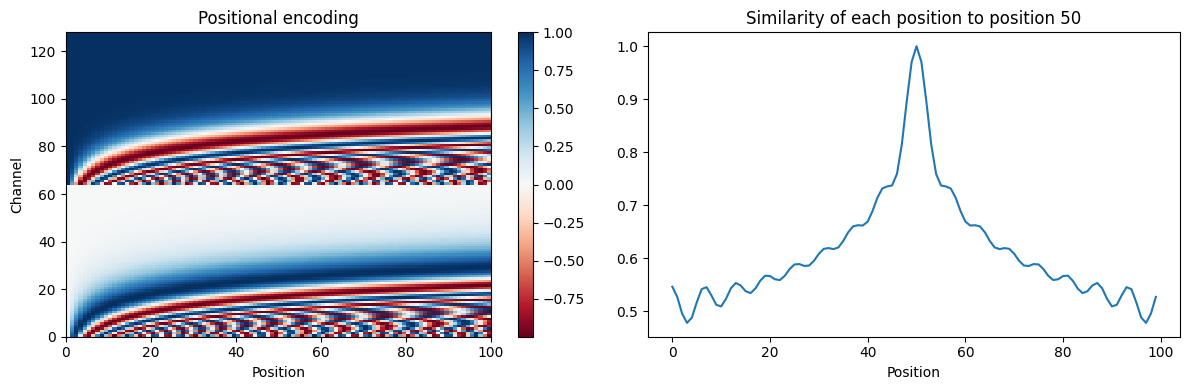

In [17]:
# A bigger picture: 100 positions, 128 channels.
encoding = positional_encoding(100, 128)

# Normalize every position vector to length 1, then compare position 50 with all the others
# using a dot product. A value of 1 means "identical direction".
normalized = encoding / np.linalg.norm(encoding, axis=1, keepdims=True)
similarity_to_position_50 = normalized @ normalized[50]

figure, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
image = left.pcolormesh(encoding.T, cmap="RdBu")        # x = position, y = channel
left.set_xlabel("Position"); left.set_ylabel("Channel"); left.set_title("Positional encoding")
figure.colorbar(image, ax=left)
right.plot(similarity_to_position_50)
right.set_xlabel("Position"); right.set_title("Similarity of each position to position 50")
plt.tight_layout()
plt.show()
# The peak at 50 and the gradual fall-off on both sides is what we wanted:
# nearby positions look alike, far-away positions look different.

## Part 4: The building blocks as Keras layers

Now we rebuild the same ideas as Keras layers that work on whole batches of sentences on a GPU, and that have *learnable* weights. First the model size. The original paper used 6 layers and 512 dimensions; we use smaller numbers so that training is quick.

In [18]:
NUM_LAYERS = 4      # how many encoder layers, and how many decoder layers
D_MODEL = 128       # the length of the vector that represents each word inside the model
NUM_HEADS = 8       # attention heads per attention layer (must divide D_MODEL evenly)
DFF = 512           # width of the hidden layer inside the feed-forward blocks
DROPOUT_RATE = 0.1  # fraction of values randomly zeroed during training, to reduce overfitting

es_vocab_size = es_vectorizer.vocabulary_size()
en_vocab_size = en_vectorizer.vocabulary_size()
print("D_MODEL per head:", D_MODEL // NUM_HEADS)

D_MODEL per head: 16


**Embedding + positional encoding.** The first layer replaces each word id by a learnable vector of length `D_MODEL` (the embedding) and adds the positional encoding from Part 3. Both the encoder and the decoder start this way.

In [19]:
class PositionalEmbedding(tf.keras.layers.Layer):
    def __init__(self, vocab_size, d_model):
        super().__init__()
        self.d_model = d_model
        # A lookup table with one learnable row of length d_model per vocabulary word.
        self.embedding = tf.keras.layers.Embedding(vocab_size, d_model)
        # The fixed (not learned) sine/cosine table from Part 3, for positions 0..MAX_LEN-1.
        self.pos_encoding = tf.cast(positional_encoding(MAX_LEN, d_model), tf.float32)

    def call(self, token_ids):
        # token_ids has shape (batch, sequence_length)
        sequence_length = tf.shape(token_ids)[1]

        x = self.embedding(token_ids)                       # (batch, sequence_length, d_model)

        # The paper multiplies the embeddings by sqrt(d_model) so that they are not
        # drowned out by the positional encoding (whose values are between -1 and 1).
        x = x * tf.math.sqrt(tf.cast(self.d_model, tf.float32))

        # Add the position vectors. We only use the first `sequence_length` rows of the table,
        # and [tf.newaxis] makes the same positions apply to every sentence in the batch.
        return x + self.pos_encoding[tf.newaxis, :sequence_length, :]

# Try it on our sample batch. The weights are random because nothing has been trained yet.
embed_es = PositionalEmbedding(es_vocab_size, D_MODEL)
embed_en = PositionalEmbedding(en_vocab_size, D_MODEL)

es_embedded = embed_es(source_ids)
en_embedded = embed_en(decoder_inputs)
print("ids      :", source_ids.shape, "->  embedded:", es_embedded.shape)
print("ids      :", decoder_inputs.shape, "->  embedded:", en_embedded.shape)

ids      : (128, 20) ->  embedded: (128, 20, 128)
ids      : (128, 21) ->  embedded: (128, 21, 128)


**Attention layers.** Keras provides `MultiHeadAttention`, which does the query/key/value projections, the scaling, softmax, weighted sum and the head-splitting for us (exactly what we did by hand in Part 2). Around it we add two things that appear in every Transformer sub-block:

* a **residual connection** (`Add`): the output is `x + attention(x)`. The layer *updates* the vectors rather than replacing them, and gradients get a direct path backwards, which makes deep stacks trainable;
* **layer normalization**: rescales each vector to a sane size so that the numbers do not drift as we stack layers.

We make one base class holding these three pieces and then three small subclasses that differ only in *what is attended to*.

In [20]:
class BaseAttention(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__()
        # kwargs are passed straight on: num_heads, key_dim, dropout.
        self.mha = tf.keras.layers.MultiHeadAttention(**kwargs)
        self.layernorm = tf.keras.layers.LayerNormalization()
        self.add = tf.keras.layers.Add()

In [21]:
class GlobalSelfAttention(BaseAttention):
    """Encoder attention: every source word looks at every source word (both directions)."""
    def call(self, x, mask=None):
        # query, key and value are all x: the sequence attends to itself.
        # `mask` hides padding positions (see the Transformer class below).
        attention_output = self.mha(query=x, key=x, value=x, attention_mask=mask)
        x = self.add([x, attention_output])      # residual connection
        return self.layernorm(x)                 # normalize

class CausalSelfAttention(BaseAttention):
    """Decoder attention: every English word looks only at itself and earlier English words."""
    def call(self, x):
        # use_causal_mask=True builds the "zeros above the diagonal" mask from Part 2 for us.
        attention_output = self.mha(query=x, key=x, value=x, use_causal_mask=True)
        x = self.add([x, attention_output])
        return self.layernorm(x)

class CrossAttention(BaseAttention):
    """Decoder attention: the English words (queries) look at the Spanish sentence (keys, values)."""
    def call(self, x, context, context_mask=None):
        # x = English side (the questions), context = encoder output for the Spanish side
        # (the dictionary being searched).
        attention_output, attention_scores = self.mha(
            query=x, key=context, value=context,
            attention_mask=context_mask,
            return_attention_scores=True)        # also give us the weights, so we can plot them

        # Remember the weights from the latest call; we plot them in Part 7.
        self.last_attention_scores = attention_scores

        x = self.add([x, attention_output])
        return self.layernorm(x)

In [22]:
# Shape checks. Every attention layer keeps the shape of the *query* sequence.
key_dim = D_MODEL // NUM_HEADS      # each head works with 128 / 8 = 16 numbers per word

global_attention = GlobalSelfAttention(num_heads=NUM_HEADS, key_dim=key_dim)
causal_attention = CausalSelfAttention(num_heads=NUM_HEADS, key_dim=key_dim)
cross_attention = CrossAttention(num_heads=NUM_HEADS, key_dim=key_dim)

print("Spanish in :", es_embedded.shape, " -> global self-attention:", global_attention(es_embedded).shape)
print("English in    :", en_embedded.shape, " -> causal self-attention:", causal_attention(en_embedded).shape)
print("English+Span. :", en_embedded.shape, " -> cross-attention      :", cross_attention(en_embedded, es_embedded).shape)
print()
print("Cross-attention weights:", cross_attention.last_attention_scores.shape,
      "= (batch, heads, English positions, Spanish positions)")

Spanish in : (128, 20, 128)  -> global self-attention: (128, 20, 128)
English in    : (128, 21, 128)  -> causal self-attention: (128, 21, 128)
English+Span. : (128, 21, 128)  -> cross-attention      : (128, 21, 128)

Cross-attention weights: (128, 8, 21, 20) = (batch, heads, English positions, Spanish positions)


In [23]:
# Sanity check that the causal mask really works. If the layer is causal, then the output for
# the first 3 English positions must be the same whether we feed it only the first 3 words
# or the whole sentence (the later words must make no difference).
output_from_3_words = causal_attention(embed_en(decoder_inputs[:, :3]))
output_from_whole_sentence = causal_attention(embed_en(decoder_inputs))[:, :3]

difference = tf.reduce_max(tf.abs(output_from_3_words - output_from_whole_sentence))
print("Largest difference:", difference.numpy(), "(should be ~0, e.g. 1e-6 or smaller)")

Largest difference: 4.7683716e-07 (should be ~0, e.g. 1e-6 or smaller)


**Feed-forward block.** After attention has mixed information *between* positions, a small two-layer neural network processes *each position separately* (the same weights at every position). It also has a residual connection and layer normalization. A common way to think about it is that attention moves information around, and the feed-forward network computes with it.

In [24]:
class FeedForward(tf.keras.layers.Layer):
    def __init__(self, d_model, dff, dropout_rate=0.1):
        super().__init__()
        self.sequence = tf.keras.Sequential([
            tf.keras.layers.Dense(dff, activation="relu"),   # expand: d_model -> dff, then ReLU
            tf.keras.layers.Dense(d_model),                  # shrink back: dff -> d_model
            tf.keras.layers.Dropout(dropout_rate),           # randomly zero some values in training
        ])
        self.add = tf.keras.layers.Add()
        self.layer_norm = tf.keras.layers.LayerNormalization()

    def call(self, x):
        x = self.add([x, self.sequence(x)])   # residual connection again
        return self.layer_norm(x)

feed_forward = FeedForward(D_MODEL, DFF)
print("Feed-forward:", en_embedded.shape, "->", feed_forward(en_embedded).shape, "(shape unchanged)")

Feed-forward: (128, 21, 128) -> (128, 21, 128) (shape unchanged)


## Part 5: The encoder and the decoder

Now we stack the pieces.

* An **encoder layer** = global self-attention, then feed-forward. The **encoder** = embedding + a stack of `NUM_LAYERS` encoder layers. It reads the Spanish sentence and outputs one rich vector per Spanish word.
* A **decoder layer** = causal self-attention, then cross-attention to the encoder output, then feed-forward. The **decoder** = embedding + a stack of decoder layers. It reads the English words written so far and, by consulting the encoder output, produces one vector per English position.

In [25]:
class EncoderLayer(tf.keras.layers.Layer):
    def __init__(self, *, d_model, num_heads, dff, dropout_rate=0.1):
        super().__init__()
        self.self_attention = GlobalSelfAttention(num_heads=num_heads,
                                                  key_dim=d_model // num_heads,
                                                  dropout=dropout_rate)
        self.ffn = FeedForward(d_model, dff, dropout_rate)

    def call(self, x, mask=None):
        x = self.self_attention(x, mask=mask)   # mix information between source words
        x = self.ffn(x)                         # then process each word separately
        return x

class Encoder(tf.keras.layers.Layer):
    def __init__(self, *, num_layers, d_model, num_heads, dff, vocab_size, dropout_rate=0.1):
        super().__init__()
        self.pos_embedding = PositionalEmbedding(vocab_size, d_model)
        self.dropout = tf.keras.layers.Dropout(dropout_rate)
        # A plain Python list of layers; we apply them one after the other in call().
        self.enc_layers = [EncoderLayer(d_model=d_model, num_heads=num_heads,
                                        dff=dff, dropout_rate=dropout_rate)
                           for _ in range(num_layers)]

    def call(self, token_ids, mask=None):
        x = self.pos_embedding(token_ids)       # (batch, source_len, d_model)
        x = self.dropout(x)
        for layer in self.enc_layers:           # the output of one layer is the input of the next
            x = layer(x, mask=mask)
        return x                                # (batch, source_len, d_model)

In [26]:
class DecoderLayer(tf.keras.layers.Layer):
    def __init__(self, *, d_model, num_heads, dff, dropout_rate=0.1):
        super().__init__()
        self.causal_self_attention = CausalSelfAttention(num_heads=num_heads,
                                                         key_dim=d_model // num_heads,
                                                         dropout=dropout_rate)
        self.cross_attention = CrossAttention(num_heads=num_heads,
                                              key_dim=d_model // num_heads,
                                              dropout=dropout_rate)
        self.ffn = FeedForward(d_model, dff, dropout_rate)

    def call(self, x, context, context_mask=None):
        x = self.causal_self_attention(x)                                # look at earlier English words
        x = self.cross_attention(x, context, context_mask=context_mask) # look at the Spanish sentence
        # Keep the cross-attention weights so we can plot them later.
        self.last_attention_scores = self.cross_attention.last_attention_scores
        x = self.ffn(x)
        return x

class Decoder(tf.keras.layers.Layer):
    def __init__(self, *, num_layers, d_model, num_heads, dff, vocab_size, dropout_rate=0.1):
        super().__init__()
        self.pos_embedding = PositionalEmbedding(vocab_size, d_model)
        self.dropout = tf.keras.layers.Dropout(dropout_rate)
        self.dec_layers = [DecoderLayer(d_model=d_model, num_heads=num_heads,
                                        dff=dff, dropout_rate=dropout_rate)
                           for _ in range(num_layers)]
        self.last_attention_scores = None

    def call(self, token_ids, context, context_mask=None):
        x = self.pos_embedding(token_ids)       # (batch, target_len, d_model)
        x = self.dropout(x)
        for layer in self.dec_layers:
            # Every decoder layer gets the SAME encoder output as its context.
            x = layer(x, context, context_mask=context_mask)
        # Keep only the weights of the last layer (enough for our plots).
        self.last_attention_scores = self.dec_layers[-1].last_attention_scores
        return x                                # (batch, target_len, d_model)

In [27]:
# Test both on the sample batch (randomly initialised, so the numbers mean nothing yet).
sample_encoder = Encoder(num_layers=NUM_LAYERS, d_model=D_MODEL, num_heads=NUM_HEADS,
                         dff=DFF, vocab_size=es_vocab_size)
sample_decoder = Decoder(num_layers=NUM_LAYERS, d_model=D_MODEL, num_heads=NUM_HEADS,
                         dff=DFF, vocab_size=en_vocab_size)

encoder_output = sample_encoder(source_ids)
decoder_output = sample_decoder(decoder_inputs, encoder_output)

print("Spanish ids :", source_ids.shape)
print("Encoder output :", encoder_output.shape, " (one vector per Spanish position)")
print("English ids    :", decoder_inputs.shape)
print("Decoder output :", decoder_output.shape, " (one vector per English position)")

Spanish ids : (128, 20)
Encoder output : (128, 20, 128)  (one vector per Spanish position)
English ids    : (128, 21)
Decoder output : (128, 21, 128)  (one vector per English position)


## Part 6: The Transformer and training

The full model glues the encoder and decoder together and adds a final `Dense` layer that turns each decoder output vector (length `D_MODEL`) into one score per English vocabulary word. These scores are called **logits**; a softmax would turn them into probabilities for the next word.

**The padding mask.** Our sentences are padded with id 0 to a fixed length. We do not want any word to attend to those padding positions, so we build a mask that is `True` where the source token is real and `False` where it is padding. Keras expects the mask to say, for each query position, which key positions it may see, so we give it the shape `(batch, 1, source_len)`, and the `1` is stretched across all queries.

In [28]:
class Transformer(tf.keras.Model):
    def __init__(self, *, num_layers, d_model, num_heads, dff,
                 source_vocab_size, target_vocab_size, dropout_rate=0.1):
        super().__init__()
        self.encoder = Encoder(num_layers=num_layers, d_model=d_model, num_heads=num_heads,
                               dff=dff, vocab_size=source_vocab_size, dropout_rate=dropout_rate)
        self.decoder = Decoder(num_layers=num_layers, d_model=d_model, num_heads=num_heads,
                               dff=dff, vocab_size=target_vocab_size, dropout_rate=dropout_rate)
        # Turns each decoder vector into one score per English vocabulary word.
        self.final_layer = tf.keras.layers.Dense(target_vocab_size)

    def call(self, inputs):
        # Keras passes all inputs as one argument; we unpack the pair (Spanish, English-so-far).
        source_ids, target_ids = inputs

        # Padding mask: True for real Spanish words, False for padding (id 0).
        source_is_real = tf.not_equal(source_ids, 0)            # (batch, source_len)
        padding_mask = source_is_real[:, tf.newaxis, :]         # (batch, 1, source_len)

        context = self.encoder(source_ids, mask=padding_mask)   # (batch, source_len, d_model)
        x = self.decoder(target_ids, context, context_mask=padding_mask)  # (batch, target_len, d_model)

        logits = self.final_layer(x)                            # (batch, target_len, en_vocab_size)
        return logits

transformer = Transformer(num_layers=NUM_LAYERS, d_model=D_MODEL, num_heads=NUM_HEADS, dff=DFF,
                          source_vocab_size=es_vocab_size, target_vocab_size=en_vocab_size,
                          dropout_rate=DROPOUT_RATE)

# Run one batch through the untrained model to check the shapes (this also builds the weights).
logits = transformer((source_ids, decoder_inputs))
print("Logits:", logits.shape, "= (batch, English positions, English vocabulary size)")
transformer.summary()

Logits: (128, 21, 10000) = (batch, English positions, English vocabulary size)


Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_1 (Encoder)             │ ?                      │     2,073,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_1 (Decoder)             │ ?                      │     2,338,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (128, 21, 10000)       │     1,290,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,701,392 (21.75 MB)

 Trainable params: 5,701,392 (21.75 MB)

 Non-trainable params: 0 (0.00 B)

**The optimizer and learning-rate schedule.** We use the Adam optimizer with the learning-rate schedule from the paper: the rate climbs linearly for the first 4000 steps (*warm-up*; large steps at the start, when the weights are random, can wreck training) and then decays like 1 over the square root of the step.

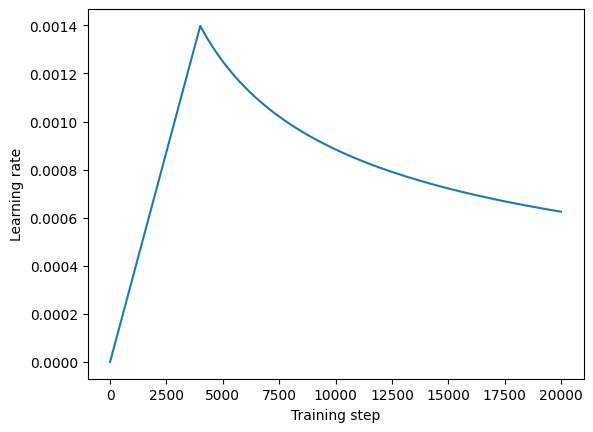

In [29]:
class CustomSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup_steps=4000):
        super().__init__()
        self.d_model = tf.cast(d_model, tf.float32)
        self.warmup_steps = warmup_steps

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        decay_part = tf.math.rsqrt(step)                       # falls as 1/sqrt(step)
        warmup_part = step * (self.warmup_steps ** -1.5)       # rises linearly with step
        # The smaller of the two wins: warm-up first, decay afterwards.
        return tf.math.rsqrt(self.d_model) * tf.math.minimum(decay_part, warmup_part)

learning_rate = CustomSchedule(D_MODEL)
optimizer = tf.keras.optimizers.Adam(learning_rate, beta_1=0.9, beta_2=0.98, epsilon=1e-9)

# Plot the schedule over 20,000 steps (start at step 1: step 0 would divide by zero).
steps = tf.range(1, 20000, dtype=tf.float32)
plt.plot(steps, learning_rate(steps))
plt.xlabel("Training step"); plt.ylabel("Learning rate"); plt.show()

**Loss and accuracy that ignore padding.** The labels are padded with zeros too. Predicting padding is trivially easy and tells us nothing, so we compute the loss (cross-entropy: how surprised the model is by the correct next word) and the accuracy only at real positions.

In [30]:
def masked_loss(labels, logits):
    # 1.0 where the label is a real word, 0.0 where it is padding.
    is_real = tf.cast(labels != 0, tf.float32)

    # Cross-entropy at every position. from_logits=True because our model outputs raw
    # scores, not probabilities. reduction="none" keeps one loss value per position.
    loss_function = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")
    loss_per_position = loss_function(labels, logits)         # (batch, target_len)

    loss_per_position = loss_per_position * is_real           # zero out padding positions
    # Average over the real positions only.
    return tf.reduce_sum(loss_per_position) / tf.reduce_sum(is_real)

def masked_accuracy(labels, logits):
    predicted_ids = tf.argmax(logits, axis=2)                 # best-scoring word at each position
    labels = tf.cast(labels, predicted_ids.dtype)
    is_real = tf.cast(labels != 0, tf.float32)
    is_correct = tf.cast(predicted_ids == labels, tf.float32) * is_real   # correct AND real
    return tf.reduce_sum(is_correct) / tf.reduce_sum(is_real)

# Before training, the model is guessing among all English words, so we expect a loss near
# ln(vocabulary size), and an accuracy close to 0.
print("Untrained loss:    ", masked_loss(labels, logits).numpy(), "  (ln(vocabulary size) is about", round(float(np.log(en_vocab_size)), 2), ")")
print("Untrained accuracy:", masked_accuracy(labels, logits).numpy())

transformer.compile(loss=masked_loss, optimizer=optimizer, metrics=[masked_accuracy])

Untrained loss:     9.197288   (ln(vocabulary size) is about 9.21 )
Untrained accuracy: 0.0


**Training.** Each epoch is one pass over the 110,000 or so training pairs. The first epoch is slower because TensorFlow compiles the model, and its progress bar may not show a total (Keras only learns the number of batches after one full pass); a couple of harmless Keras warnings may also appear. Watch the loss go down and the accuracy go up, and watch `val_` numbers too: those are measured on sentences the model never trains on.

If you are short on time, lower `EPOCHS`; more epochs give better translations, with diminishing returns.

In [ ]:
EPOCHS = 10

history = transformer.fit(train_batches,
                          epochs=EPOCHS,
                          validation_data=val_batches)

Epoch 1/10
    881/Unknown 121s 73ms/step - loss: 7.4810 - masked_accuracy: 0.2033

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


881/881 ━━━━━━━━━━━━━━━━━━━━ 133s 86ms/step - loss: 5.7673 - masked_accuracy: 0.3093 - val_loss: 3.3120 - val_masked_accuracy: 0.4849
Epoch 2/10
684/881 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - loss: 2.9678 - masked_accuracy: 0.5295

In [ ]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

left.plot(history.history["loss"], label="training")
left.plot(history.history["val_loss"], label="validation")
left.set_xlabel("Epoch"); left.set_ylabel("Loss"); left.legend()

right.plot(history.history["masked_accuracy"], label="training")
right.plot(history.history["val_masked_accuracy"], label="validation")
right.set_xlabel("Epoch"); right.set_ylabel("Accuracy of next-word prediction"); right.legend()

plt.tight_layout(); plt.show()
# If the training curve keeps improving while the validation curve flattens or gets worse,
# the model is starting to memorize the training set (overfitting).

## Part 7: Translating

At training time one forward pass predicts the next word at *every* position at once (teacher forcing). At inference time we do not have the English sentence, so we must generate it **one word at a time**:

1. Encode the Spanish sentence.
2. Start the English output with `[start]`.
3. Run the model, take the scores at the **last** position, and pick the best word (**greedy decoding**).
4. Append that word to the output and go back to step 3, until the model emits `[end]` (or we hit the length limit).

This loop is also what an LLM does when it writes text to you, one token at a time, feeding each token back in.

In [ ]:
def translate(sentence, model=transformer):
    # The vectorizer cleans the text with standardize_text by itself. We call the same function
    # once more only to get the list of words that we label the attention plots with.
    cleaned = standardize_text(tf.constant(sentence)).numpy().decode("utf-8")
    source_words = cleaned.split()[:MAX_WORDS]
    source_ids = es_vectorizer([sentence])                  # (1, MAX_WORDS) ids, padded with 0

    output_ids = [start_id]                                 # the English output so far
    for step in range(MAX_LEN - 1):
        decoder_input = tf.constant([output_ids])           # (1, current length)
        logits = model((source_ids, decoder_input), training=False)   # (1, current length, vocab)

        # Only the LAST position is new information: it predicts the next word.
        # (NOTE: a real implementation would cache the earlier positions instead of
        # recomputing them every step. We recompute for simplicity.)
        next_id = int(tf.argmax(logits[0, -1]))             # greedy: take the highest score
        output_ids.append(next_id)
        if next_id == end_id:                               # the model says "I am finished"
            break

    # Run the model once more on the finished output to get the cross-attention weights.
    # The decoder inputs are the output without its last token (labels are shifted by one).
    model((source_ids, tf.constant([output_ids[:-1]])), training=False)
    all_scores = model.decoder.last_attention_scores        # (1, heads, output positions, MAX_WORDS)
    attention = all_scores[0].numpy()[:, :, :len(source_words)]   # drop the padding columns

    output_words = [en_vocab[i] for i in output_ids[1:]]    # leave out [start]
    translation = " ".join(word for word in output_words if word != "[end]")
    return translation, source_words, output_words, attention

def show_translation(sentence, ground_truth=None):
    translation, _, _, _ = translate(sentence)
    print("Input       :", sentence)
    print("Translation :", translation)
    if ground_truth is not None:
        print("Ground truth:", ground_truth)
    print()

# Sentences written by hand (they are not in the dataset).
show_translation("¿Dónde está la biblioteca?")
show_translation("Me gustaría un café, por favor.")
show_translation("Ella siempre llega tarde a la escuela.")
show_translation("No sé qué hacer ahora.")
show_translation("Mañana vamos a visitar a mis abuelos.")

In [ ]:
# Sentences from the test set, which the model never trained on (and never used for monitoring).
for spanish, english in test_examples.take(5):
    show_translation(spanish.numpy().decode("utf-8"), english.numpy().decode("utf-8"))

**Looking inside: attention plots.** The cross-attention weights show, for each English word the model wrote (rows), how much it looked at each Spanish word (columns). Brighter means more attention. Each of the 8 heads is a separate panel, and different heads learn different habits. Many translation heads are roughly diagonal, because word order is similar in the two languages.

In [ ]:
def plot_attention_heads(source_words, output_words, attention):
    # attention has shape (heads, output words, source words)
    number_of_heads = attention.shape[0]
    rows = int(np.ceil(number_of_heads / 4))        # 4 panels per row
    figure = plt.figure(figsize=(16, 4 * rows))
    for head in range(number_of_heads):
        axis = figure.add_subplot(rows, 4, head + 1)
        axis.matshow(attention[head])               # draw the weights as a coloured grid
        axis.set_xticks(range(len(source_words)))
        axis.set_xticklabels(source_words, rotation=90)
        axis.set_yticks(range(len(output_words)))
        axis.set_yticklabels(output_words)
        axis.set_xlabel(f"Head {head + 1}")
    plt.tight_layout()
    plt.show()

sentence = "Ella siempre llega tarde a la escuela."
translation, source_words, output_words, attention = translate(sentence)
print("Translation:", translation)
plot_attention_heads(source_words, output_words, attention)

**Words the tokenizer has never seen.** Our tokenizer has a vocabulary of 10,000 words per language. Anything else becomes `[UNK]` (id 1), and the model cannot know what the word was. Real LLMs avoid this with *subword* tokenizers (BPE, WordPiece): a rare word is split into smaller known pieces such as `tri` + `cera` + `tops`, so nothing is ever completely unknown.

In [ ]:
sentence = "El triceratops vivió hace millones de años."
ids = es_vectorizer([sentence]).numpy()[0]
print("Tokens the model sees:", ids_to_words(ids, es_vocab))
print("(A word shown as [UNK] was not among the 10,000 most frequent Spanish words: the model cannot see it.)")
print()
show_translation(sentence)

## Part 8: Experiments and questions

**Experiments.** Each one means changing a few lines and re-running from the cell that creates the model (use `EPOCHS = 3` or `5` to keep it quick, and compare against a baseline with the *same* number of epochs).

1. **Remove the causal mask.** In `CausalSelfAttention`, delete `use_causal_mask=True` and retrain. What happens to the training accuracy? Now translate a sentence. Explain the difference. *(Hint: what does the decoder get to see during training that it will not have at inference time?)*
2. **Heads and depth.** Try `NUM_HEADS = 1` and then `NUM_LAYERS = 1` or `2`. How do the validation loss and the quality of translations change?
3. **Remove positional information.** In `PositionalEmbedding.call`, return `x` without adding the positional encoding. The model now sees a bag of words. Which kinds of sentences does it get wrong?
4. **Decoding.** Greedy decoding always takes the best word. In `translate`, replace `tf.argmax(...)` by sampling: `next_id = int(tf.random.categorical(logits[:, -1] / temperature, 1)[0, 0])`, with `temperature = 0.7` and then `1.5`. What does temperature do to the output? This is the same knob you meet in LLM APIs.
5. **Tokenization.** Translate a few sentences containing rare words. How often do you see `[UNK]`-related mistakes? Try `VOCAB_SIZE = 3000` and `VOCAB_SIZE = 20000` (this changes the tokenizers, so re-run from Part 1).

**Questions to check your understanding**

1. Why do we divide the attention scores by the square root of the vector length?
2. The decoder layer has *two* attention blocks. What does each one look at, and why do we need both?
3. Training computes predictions for all positions in a single forward pass, but translation needs a loop. Why can training skip the loop?
4. Which parts of this model would you delete to turn it into a GPT-style, decoder-only language model, and what would the model then be trained on?
5. Our validation sentences can have near-duplicates in the training set (the same English sentence with another Spanish translation). Why does that make validation accuracy optimistic, and how would you build a fairer split?

**Simplifications made for teaching.** The tokenizer is word-level; decoding is greedy and recomputes earlier positions at every step (real systems use a key/value cache and beam search or sampling); and we only plot the last decoder layer's cross-attention.